#### General Imports

In [114]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os 
os.chdir('D:\Machine Learning\Datasets')
import warnings
warnings.filterwarnings('ignore')

#### Sklearn Imports

In [115]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import root_mean_squared_error


#### Torch imports

In [116]:
import torch
import torch.nn as nn
from torch.autograd import Variable

In [117]:
test_size = 24 #
seq_length = 10 # time steps should be less than test size


In [118]:
dataset_ts = pd.read_csv('AirPassengers.csv')
dataset_train = dataset_ts.iloc[:-test_size,:10].values
dataset_test = dataset_ts.iloc[-test_size:,:10].values
training_set = dataset_train[:,1:2]
testing_set = dataset_test[:,1:2]
sc = MinMaxScaler()
training_set_scaled = sc.fit_transform(training_set)
testing_set_scaled = sc.transform(testing_set)
training_set_scaled.shape, testing_set_scaled.shape

((120, 1), (24, 1))

In [119]:
def sliding_window(data, seq_length):
    x=[]
    y=[]
    for i in range(len(data)-seq_length - 1):
        _x=data[i:(i+seq_length)]
        _y=data[i+seq_length]
        x.append(_x)
        y.append(_y)

    return np.array(x), np.array(y)

In [120]:
X_train, y_train = sliding_window(training_set_scaled, seq_length)
X_test, y_test = sliding_window(testing_set_scaled, seq_length)
X_train.shape, X_test.shape, y_train.shape,y_test.shape

((109, 10, 1), (13, 10, 1), (109, 1), (13, 1))

In [121]:
trainX = Variable(torch.Tensor(np.array(X_train)))
trainY = Variable(torch.Tensor(np.array(y_train)))

testX = Variable(torch.Tensor(np.array(X_test)))
testY = Variable(torch.Tensor(np.array(y_test)))

trainX.shape, trainY.shape, testX.shape, testY.shape

(torch.Size([109, 10, 1]),
 torch.Size([109, 1]),
 torch.Size([13, 10, 1]),
 torch.Size([13, 1]))

In [122]:
class LSTM(nn.Module):
    def __init__(self, num_classes, input_size, hidden_size, num_layers):
        super(LSTM, self).__init__()

        self.num_classes = num_classes
        self.num_layers = num_layers
        self.input_size = input_size
        self.hidden_size = hidden_size

        self.lstm = nn.LSTM(input_size=input_size,
                            hidden_size=hidden_size,
                            num_layers=num_layers,
                            batch_first=True)
        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        h_0 = Variable(torch.zeros( self.num_layers, x.size(0), self.hidden_size))
        c_0 = Variable(torch.zeros( self.num_layers, x.size(0), self.hidden_size)) # Memory state
        ula, (h_out, _) = self.lstm(x,(h_0, c_0)) # propogate input through LSTM
        h_out = h_out.view(-1, self.hidden_size)
        out = self.fc(h_out)

        return out

In [128]:
learning_rate , num_epochs= 0.01,2000
input_size, hidden_size, num_layers, num_classes = 1,2,1,1
lstm = LSTM(num_classes, input_size, hidden_size, num_layers)
criterion = torch.nn.MSELoss()
optimizer = torch.optim.Adam(lstm.parameters(), lr = learning_rate)
for epoch in range(num_epochs):
    outputs = lstm(trainX)
    optimizer.zero_grad()
    loss = criterion(outputs, trainY)
    loss.backward()
    if epoch % 100 == 0:
        print("Epoch: %d, loss: %1.5f " % (epoch, loss.item()))

Epoch: 0, loss: 0.07536 
Epoch: 100, loss: 0.07536 
Epoch: 200, loss: 0.07536 
Epoch: 300, loss: 0.07536 
Epoch: 400, loss: 0.07536 
Epoch: 500, loss: 0.07536 
Epoch: 600, loss: 0.07536 
Epoch: 700, loss: 0.07536 
Epoch: 800, loss: 0.07536 
Epoch: 900, loss: 0.07536 
Epoch: 1000, loss: 0.07536 
Epoch: 1100, loss: 0.07536 
Epoch: 1200, loss: 0.07536 
Epoch: 1300, loss: 0.07536 
Epoch: 1400, loss: 0.07536 
Epoch: 1500, loss: 0.07536 
Epoch: 1600, loss: 0.07536 
Epoch: 1700, loss: 0.07536 
Epoch: 1800, loss: 0.07536 
Epoch: 1900, loss: 0.07536 


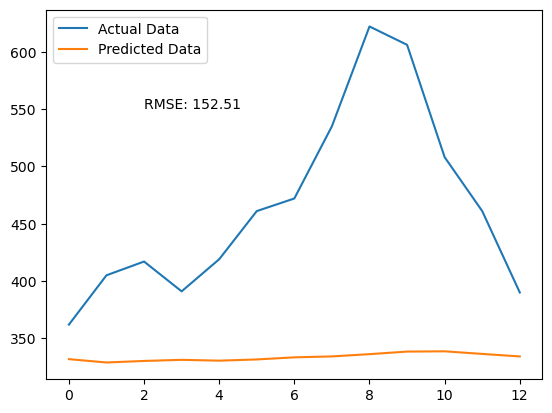

In [129]:
lstm.eval()
test_predict = lstm(testX)
data_predict = test_predict.data.numpy()
dataY_plot = testY.data.numpy()
data_predict = sc.inverse_transform(data_predict)
dataY_plot = sc.inverse_transform(dataY_plot)
plt.plot(dataY_plot, label = 'Actual Data')
plt.plot(data_predict, label='Predicted Data')
rmse = root_mean_squared_error(dataY_plot, data_predict)
plt.legend()
plt.text(2,550,"RMSE: %.2f" % rmse)
plt.show()

In [131]:
## Dataset - FRED ROUST.CSV
# test_size = last 8 


In [132]:
test_size = 8
seq_length = 3

In [133]:
dataset_ts = pd.read_csv('FRED-NROUST.csv')
dataset_ts.head()

,Date,Value
0,01-01-1949,5.255053
1,01-04-1949,5.261516
2,01-07-1949,5.268013
3,01-10-1949,5.274564
4,01-01-1950,5.281182
